# Data Cleaning Procedure

In [63]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [64]:
FILES = [
    "TM_applicant_classification_2025-01-28.csv",
    "TM_application_main_2025-01-28.csv",
    "TM_cipo_classification_2025-01-28.csv",
]

# Keep every table, keyed by file name, so none is overwritten by the next one.
tables = {}
for FILE in FILES:
    DATA_PATH = Path.cwd().parents[1] / "data" / FILE

    # The files are large and pipe-delimited, so only read the first 10 rows.
    # Application numbers keep their leading zeros by being read as strings.
    tables[FILE] = pd.read_csv(
        DATA_PATH,
        sep="|",
        nrows=10,
        encoding="utf-8",
        dtype={0: str},
    )

    # Strip stray whitespace from the bilingual column headers
    #tables[FILE].columns = tables[FILE].columns.str.strip()

    # A bare variable inside a loop is not shown; display() renders each table.
    print(FILE)
    display(tables[FILE])


TM_applicant_classification_2025-01-28.csv


,Application Number - Numéro de la demande,Classification Sequence Number - Numéro de séquence de la classification,Classification Indicator Line Sequence Number - Ligne indicatrice du numéro de séquence de la classification,Nice Edition Number - Numéro d’édition de classification de Nice,Nice Classification Code - Code de de classification de Nice,Nice Classification - Classification de Nice,Classification indicator description - Description de l'indicateur de la classification
0,0000111,Goods1,1,-1,-1,Unknown,Pharmaceutical preparation namely a tonic.
1,0001031,Goods1,1,-1,-1,Unknown,"Spirits, to wit, whiskey."
2,0001299,Goods1,1,-1,-1,Unknown,Pomatum for the hair.
3,0001507,Goods1,1,-1,-1,Unknown,Self-raising flour.
4,0001745,Goods1,1,-1,-1,Unknown,Sewing machines and parts thereof.
5,0002223,Goods1,1,-1,-1,Unknown,"Preserved minced meat, canned fish, bakery pro..."
6,0002223,Goods2,1,-1,-1,Unknown,Soups and substances used in preparation of so...
7,0002328,Goods1,1,-1,-1,Unknown,Beer.
8,0002402,Produits1,1,-1,-1,Unknown,Sirop de gomme d'epinette compose.
9,0002412,Goods1,1,-1,-1,Unknown,Axes


TM_application_main_2025-01-28.csv


,Application Number - Numéro de la demande,Filing Date - Date de dépôt,Publication Date - Date de publication,Registration Date - Date d’enregistrement,Registration Office Country Code - Code du pays de l’office de l’enregistrement,Receiving Office Country Code - Code du pays de l’office récepteur,Receiving Office Date - Date de réception par l’office,Assigning Office Country Code - Code du pays de l'office de cession,Registration Number - Numéro d’enregistrement,Legislation Description Code - Code de description de la législation (Code de Loi applicable),...,Application Abandoned Date - Date d’abandon de la demande,CIPO Status Code - Code de statut de la marque,Allowed Date - Date admise,Renewal Date - Date de renouvellement,Trademark Class Code - Code de la classe de marque,Geographical Indication Kind Category Code - Code du type d’indication géographique,Geographical Indication Translation Sequence Number - Numéro d’ordre de traduction de l’indication géographique,Geographical IndicationTranslationText - Texte de la traduction de l’indication géographique,Doubtful Case Application Number - Numéro de demande du cas douteux,Doubtful Case Registration Number - Numéro d’enregistrement du cas douteux
0,0000111,NaN,NaN,1869-01-04,CA,CA,NaN,CA,TMDA18,3,...,NaN,13,NaN,1972-09-01,7,Unknown,NaN,NaN,NaN,NaN
1,0001031,NaN,NaN,1871-09-26,CA,CA,2017-07-26,CA,TMDA226,3,...,NaN,12,NaN,2017-09-01,7,Unknown,NaN,NaN,NaN,NaN
2,0001299,NaN,NaN,1872-04-18,CA,CA,NaN,CA,TMDA300,3,...,NaN,13,NaN,1987-09-01,7,Unknown,NaN,NaN,NaN,NaN
3,0001368,NaN,NaN,NaN,CA,CA,NaN,CA,NaN,1,...,NaN,32,NaN,NaN,1,Unknown,NaN,NaN,NaN,NaN
4,0001507,1872-12-14,NaN,1872-12-14,CA,CA,NaN,CA,TMDA359,3,...,NaN,13,NaN,NaN,1,Unknown,NaN,NaN,NaN,NaN
5,0001745,NaN,NaN,1873-08-01,CA,CA,NaN,CA,TMDA421,3,...,NaN,13,NaN,1987-09-01,7,Unknown,NaN,NaN,NaN,NaN
6,0001759,NaN,NaN,NaN,CA,CA,NaN,CA,NaN,1,...,NaN,32,NaN,NaN,1,Unknown,NaN,NaN,NaN,NaN
7,0002223,NaN,NaN,1874-10-09,CA,CA,2017-08-31,CA,TMDA538,3,...,NaN,12,NaN,2017-09-01,7,Unknown,NaN,NaN,NaN,NaN
8,0002328,NaN,NaN,1875-01-07,CA,CA,2017-01-09,CA,TMDA622,3,...,NaN,12,NaN,2017-09-01,7,Unknown,NaN,NaN,NaN,NaN
9,0002402,NaN,NaN,1875-03-09,CA,CA,NaN,CA,TMDA652,3,...,NaN,13,NaN,1972-09-01,12,Unknown,NaN,NaN,NaN,NaN


TM_cipo_classification_2025-01-28.csv


,Application Number - Numéro de la demande,Classification Kind Code - Code du type de classification,Nice Classification Code - Code de Classification de Nice
0,0000111,Nice,5
1,0001031,Nice,33
2,0001299,Nice,3
3,0001507,Nice,30
4,0001745,Nice,7
5,0002223,Nice,30
6,0002223,Nice,29
7,0002328,Nice,32
8,0002402,Nice,30
9,0002412,Nice,8


## Trademarks registered in 2024

**Method choice.** The three files don't share columns, and their rows don't line up one-to-one: one application has a single row in *application_main*, one row per goods/services line in *applicant_classification*, and one row per Nice class in *cipo_classification*. So "concatenate then filter" really means joining all three files in full. Each 62-column main row would be repeated (goods lines × Nice classes) times for every application ever filed. That is about 3.2 GB of text, which grows to tens of GB in pandas memory before the 2024 filter throws most of it away.

**Filter first** reads each file once, the same amount of disk work. It streams the file in chunks and keeps only the rows whose application number was registered in 2024. Memory stays at about one chunk plus the small result, so this is the method used.

The result has one row per application number: the main columns, the Nice classes from *cipo_classification* (`Nice Code`), the goods/services text from *applicant_classification*, and the logo's Vienna codes from *representation* (`Vienna Code`). *representation* is a fourth file from the same release, filtered the same way. It is written to `../../pool/` (next to `data/`, outside the repo) instead of being kept in the notebook.

In [65]:
import csv

DATA_DIR = Path.cwd().parents[1] / "data"
POOL_DIR = Path.cwd().parents[1] / "pool"
POOL_DIR.mkdir(exist_ok=True)

YEAR = "2024"
CHUNK = 250_000
# The files never quote fields, but some text starts with a stray '"'.
# QUOTE_NONE stops pandas from treating it as an opening quote.
READ_OPTS = dict(sep="|", encoding="utf-8", dtype=str, chunksize=CHUNK, quoting=csv.QUOTE_NONE)


def short_names(columns):
    """Keep only the English half of the bilingual headers ("English - Français")."""
    return [c.split(" - ")[0].strip() for c in columns]


def stream_filtered(file, keep):
    """Read a file in chunks, keeping only rows that pass `keep(chunk)`."""
    parts = []
    for chunk in pd.read_csv(DATA_DIR / file, **READ_OPTS):
        chunk.columns = short_names(chunk.columns)
        parts.append(chunk[keep(chunk)])
    return pd.concat(parts, ignore_index=True)


def build_registered(year):
    # 1. Applications registered in `year` (dates are ISO, e.g. 2024-03-15).
    main = stream_filtered(
        "TM_application_main_2025-01-28.csv",
        lambda c: c["Registration Date"].str.startswith(year, na=False),
    ).set_index("Application Number")
    ids = set(main.index)
    in_ids = lambda c: c["Application Number"].isin(ids)

    # 2. CIPO Nice classes: one row per class -> "05;33".
    cipo = stream_filtered("TM_cipo_classification_2025-01-28.csv", in_ids)
    nice = (
        cipo.sort_values("Nice Classification Code")
        .groupby("Application Number")["Nice Classification Code"]
        .agg(lambda s: ";".join(s.dropna().unique()))
        .rename("Nice Code")
    )

    # 3. Goods/services -> one text per application.
    #    Each "Classification Sequence Number" (Goods1, Services1, Produits1 = French goods)
    #    is one statement, usually one per Nice class. A statement lists several goods
    #    separated by ";". Statements longer than 4,000 characters are cut into
    #    several rows ("line" 1, 2, ...) mid-sentence, so they are rejoined with no separator.
    cls = stream_filtered("TM_applicant_classification_2025-01-28.csv", in_ids)
    seq = cls["Classification Sequence Number"].str.extract(r"^(\D+)(\d+)$")
    cls["kind"] = seq[0].map({"Goods": 0, "Produits": 0, "Services": 1})
    cls["seq"] = seq[1].astype(int)
    cls["line"] = pd.to_numeric(cls["Classification Indicator Line Sequence Number"], errors="coerce")
    cls = cls.sort_values(["Application Number", "kind", "seq", "line"])

    statements = (
        cls.groupby(["Application Number", "Classification Sequence Number"], sort=False)
        ["Classification indicator description"]
        .agg(lambda s: "".join(s.dropna()).strip())
    )
    # Drop identical statements repeated within one application.
    statements = statements[~statements.reset_index().duplicated(
        ["Application Number", "Classification indicator description"]).to_numpy()]
    items = statements.str.split(";").apply(lambda xs: sum(bool(x.strip()) for x in xs))

    by_app = statements.groupby(level="Application Number", sort=False)
    goods = pd.DataFrame({
        "Goods Services Statements": by_app.size(),
        "Goods Services Items": items.groupby(level="Application Number", sort=False).sum(),
        "Goods Services Description": by_app.agg(" || ".join),
    })

    # 4. Vienna codes (what a logo shows): category.division.section per row -> "26.4.2;27.5.1".
    #    Only the three code parts are kept; descriptions, image and colour columns are dropped.
    #    -1 is a placeholder for "no code".
    rep = stream_filtered("TM_representation_2025-01-28.csv", in_ids)
    parts = ["Vienna Code", "Vienna Division Number", "Vienna Section Number"]
    rep[parts] = rep[parts].apply(pd.to_numeric, errors="coerce")
    rep = rep.dropna(subset=parts)
    rep = rep[(rep[parts] >= 0).all(axis=1)].astype({p: int for p in parts})
    rep = rep.sort_values(["Application Number"] + parts)
    rep["code"] = rep[parts].astype(str).agg(".".join, axis=1)
    vienna = (
        rep.drop_duplicates(["Application Number", "code"])
        .groupby("Application Number")["code"]
        .agg(";".join)
        .rename("Vienna Code")
    )

    # 5. One row per application number. Applications with no goods/services
    #    lines get NaN; Int64 keeps the counts whole numbers despite that.
    merged = main.join(nice).join(goods).join(vienna)
    for col in ["Goods Services Statements", "Goods Services Items"]:
        merged[col] = merged[col].astype("Int64")
    return merged


out_file = POOL_DIR / f"TM_registered_{YEAR}.csv"
registered = build_registered(YEAR)
registered.to_csv(out_file, sep="|", encoding="utf-8")
print(f"{len(registered):,} applications x {registered.shape[1]} columns")
del registered  # keep the notebook light; reload from the file when needed
print(f"Saved {out_file}")


62,586 applications x 66 columns
Saved d:\Coding\Github\green_innovation_screening_all\pool\TM_registered_2024.csv


In [66]:
POOL_PATH = Path.cwd().parents[1] / "pool" / "TM_registered_2024.csv"

# Read the whole file (no nrows): it is sorted by application number, so the first
# rows are old official marks, not ordinary trademarks.
# dtype=str keeps leading zeros and avoids mixed-type warnings.
pool = pd.read_csv(
    POOL_PATH,
    sep="|",
    encoding="utf-8",
    dtype=str,
    index_col="Application Number",
)

pool.columns

Index(['Filing Date', 'Publication Date', 'Registration Date',
       'Registration Office Country Code', 'Receiving Office Country Code',
       'Receiving Office Date', 'Assigning Office Country Code',
       'Registration Number', 'Legislation Description Code', 'Filing Place',
       'Application Reference Number', 'Application Language Code',
       'Expiry Date', 'Termination Date', 'WIPO Status Code',
       'Current Status Date', 'Association Category ID',
       'Association Assigning Country Code', 'Associated Application Number',
       'Mark Category', 'Divisional Application Country Code',
       'Divisional Application Number', 'Divisional Application Date',
       'Internationall Registration Number', 'MarkType Code',
       'Mark Verbal Element Description', 'Mark Significant Description',
       'Mark Translation Description', 'Expungement Indicator',
       'Distinctiveness Indicator', 'Distinctiveness Description',
       'Evidence Of Use Indicator', 'Evidence Of Use

In [67]:
features = [
    "Mark Significant Description",
    "MarkType Code",
    "Trademark Class Code",
    "Goods Services Statements",
    "Goods Services Items",
    "Goods Services Description",
    "Nice Code",
    "Vienna Code",
]

# Keep ordinary trademarks only (Trademark Class Code 1). Codes are read as text.
pool = pool.loc[pool["Trademark Class Code"] == "1", features]
pool=pool.drop('Trademark Class Code',axis=1)

# Data representation

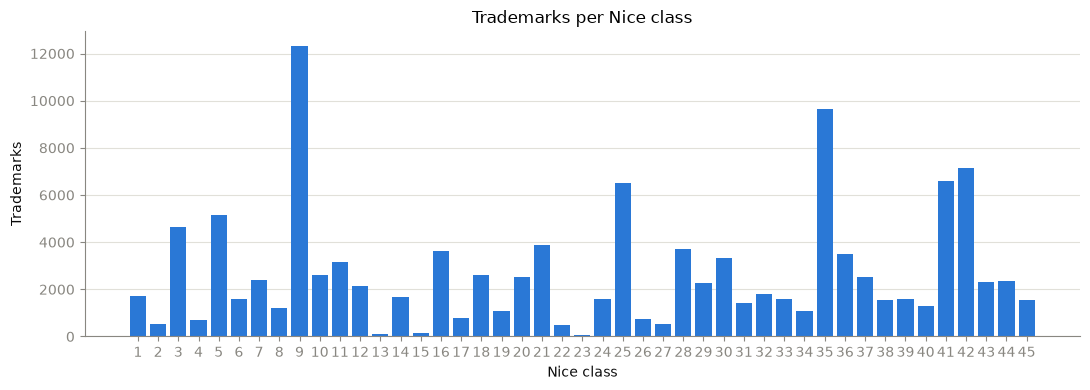

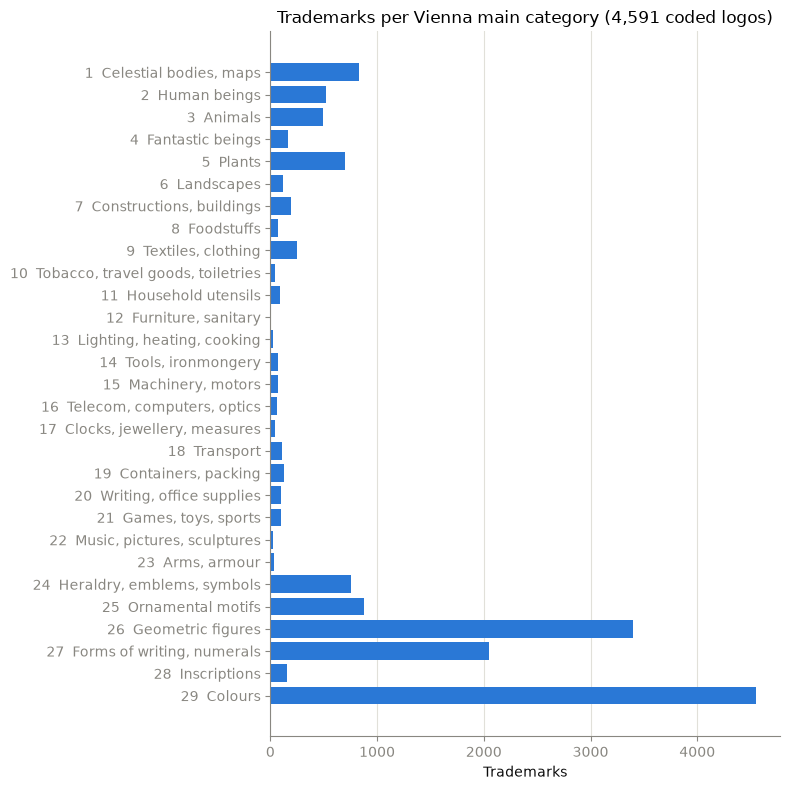

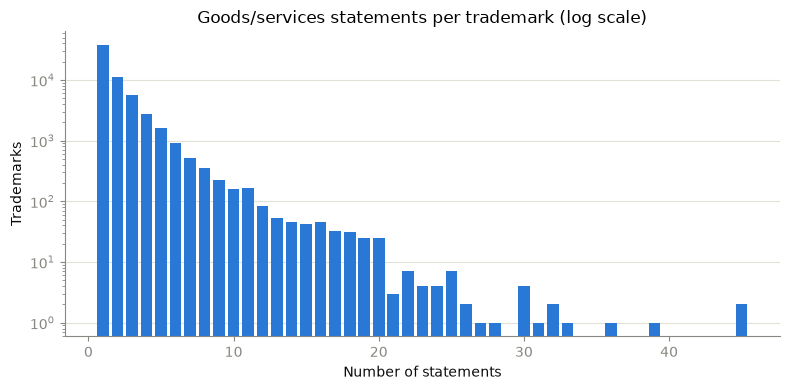

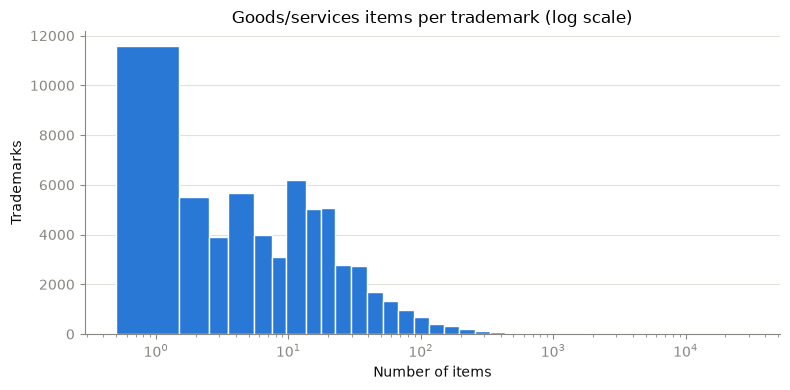

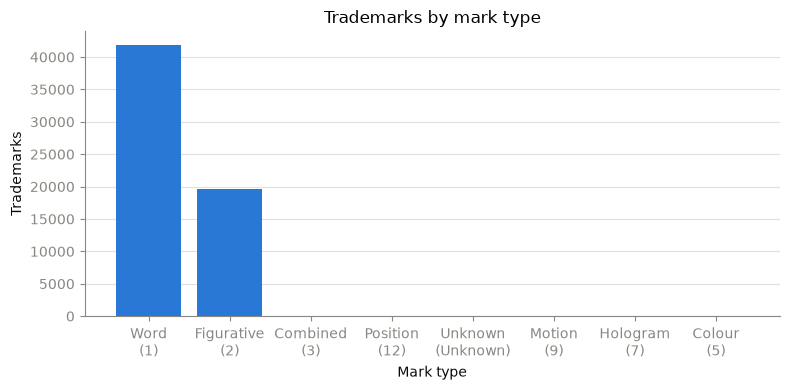

In [68]:
BAR = "#2a78d6"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e1e0d9",
                     "axes.axisbelow": True})

# Code meanings from CIPO's data dictionary (MarkType = WIPO mark format).
MARK_TYPES = {"1": "Word", "2": "Figurative", "3": "Combined", "4": "3D", "5": "Colour",
              "6": "Sound", "7": "Hologram", "8": "Olfactory", "9": "Motion",
              "10": "Touch", "11": "Taste", "12": "Position", "13": "Other"}


def plot_counts(counts, title, xlabel, figsize=(8, 4), log=False):
    """One bar per value, with a centred title. log=True puts the y-axis on a log scale."""
    fig, ax = plt.subplots(figsize=figsize)
    ax.bar(counts.index, counts.values, color=BAR)
    if log:
        ax.set_yscale("log")
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Trademarks")
    plt.tight_layout()
    plt.show()


# Temporary long table for Nice classes: one row per (trademark, class).
nice_long = (
    pool["Nice Code"].dropna()
    .str.split(";").explode()
    .rename("Nice Class").reset_index()
)
nice_counts = nice_long["Nice Class"].astype(int).value_counts().sort_index()
nice_counts.index = nice_counts.index.astype(str)  # one labelled bar per class, 1-45
plot_counts(nice_counts, "Trademarks per Nice class", "Nice class", figsize=(11, 4))

# Vienna main categories (WIPO Vienna Classification, short names).
VIENNA_CATEGORIES = {
    1: "Celestial bodies, maps", 2: "Human beings", 3: "Animals", 4: "Fantastic beings",
    5: "Plants", 6: "Landscapes", 7: "Constructions, buildings", 8: "Foodstuffs",
    9: "Textiles, clothing", 10: "Tobacco, travel goods, toiletries", 11: "Household utensils",
    12: "Furniture, sanitary", 13: "Lighting, heating, cooking", 14: "Tools, ironmongery",
    15: "Machinery, motors", 16: "Telecom, computers, optics", 17: "Clocks, jewellery, measures",
    18: "Transport", 19: "Containers, packing", 20: "Writing, office supplies",
    21: "Games, toys, sports", 22: "Music, pictures, sculptures", 23: "Arms, armour",
    24: "Heraldry, emblems, symbols", 25: "Ornamental motifs", 26: "Geometric figures",
    27: "Forms of writing, numerals", 28: "Inscriptions", 29: "Colours",
}

# Temporary long table: one row per (trademark, Vienna main category).
# A mark with several codes in the same category counts once for it.
vienna_long = (
    pool["Vienna Code"].dropna()
    .str.split(";").explode()
    .str.split(".").str[0].astype(int)
    .rename("Vienna Category").reset_index()
    .drop_duplicates()
)
vienna_counts = vienna_long["Vienna Category"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(8, 8))
ax.barh([f"{c}  {VIENNA_CATEGORIES.get(c, '')}" for c in vienna_counts.index],
        vienna_counts.values, color=BAR)
ax.invert_yaxis()  # category 1 at the top
ax.grid(axis="x", color="#e1e0d9")
ax.grid(axis="y", visible=False)
ax.set_title(f"Trademarks per Vienna main category ({pool['Vienna Code'].notna().sum():,} coded logos)")
ax.set_xlabel("Trademarks")
plt.tight_layout()
plt.show()

statements = pd.to_numeric(pool["Goods Services Statements"]).dropna().astype(int)
plot_counts(statements.value_counts().sort_index(),
            "Goods/services statements per trademark (log scale)", "Number of statements",
            log=True)

items = pd.to_numeric(pool["Goods Services Items"]).dropna()
fig, ax = plt.subplots(figsize=(8, 4))
# Log-spaced bins snapped to whole numbers, on a log x-axis (max is ~30,000 items).
bins = np.unique(np.geomspace(1, items.max() + 1, 40).astype(int)) - 0.5
ax.hist(items, bins=bins, color=BAR, edgecolor="white")
ax.set_xscale("log")
ax.set_title("Goods/services items per trademark (log scale)")
ax.set_xlabel("Number of items")
ax.set_ylabel("Trademarks")
plt.tight_layout()
plt.show()

mark_types = pool["MarkType Code"].fillna("Missing").value_counts()
mark_types.index = [f"{MARK_TYPES.get(c, c)}\n({c})" for c in mark_types.index]
plot_counts(mark_types, "Trademarks by mark type", "Mark type")


In [69]:
# Trademarks listing more than 200 goods/services items (the long tail of the histogram).
items = pd.to_numeric(pool["Goods Services Items"])
over_200 = pool[items > 200].assign(**{"Goods Services Items": items}).sort_values(
    "Goods Services Items", ascending=False
)

print(f"{len(over_200):,} trademarks have more than 200 items")
over_200


604 trademarks have more than 200 items


,Mark Significant Description,MarkType Code,Goods Services Statements,Goods Services Items,Goods Services Description,Nice Code,Vienna Code
Application Number,,,,,,,
2176749,ENERJO,1,18,29781,2-naphthol; absorbent expandable graphites; ab...,01;04;05;06;07;08;09;10;11;12;14;31;35;37;38;3...,NaN
2155222,NaN,2,13,13137,Accordion doors of metal; acoustic panels of m...,06;08;14;16;17;18;21;24;25;26;28;31;32;33,NaN
2176990,FLOWERICA,1,10,13060,2-naphthol; absorbent expandable graphites; ab...,01;08;14;21;24;25;31;35;39;44,NaN
2206907,NaN,2,6,11420,"Additives, non-chemical, to motor fuel; alcoho...",04;08;09;16;21,NaN
2189969,SISDATA,1,1,9780,35mm cameras; 360-degree camcorders; 360-degre...,09,NaN
...,...,...,...,...,...,...,...
2127102,Fsedh,1,4,202,Bag hangers of plastic; barrels and casks for ...,06;20;21;28;35,NaN
2153722,HAO LAI (SIMPLIFIED CHINESE CHARACTERS),2,5,201,After-sun creams for cosmetic purposes; air fr...,03;05;10;21;30,NaN
2071314,TCHOTCHKE,1,10,201,Key chains of plastic; plastic key chain tags....,14;16;18;20;21;24;25;28;31,NaN


In [70]:
# Goods/services listed by ENERJO (application 2176749), one item per row.
# " || " separates statements (roughly one per Nice class); ";" separates items inside a statement.
enerjo = pool.loc[pool["Mark Significant Description"] == "ENERJO"]
description = enerjo["Goods Services Description"].iloc[0]

enerjo_items = pd.DataFrame(
    [
        {"Statement": n, "Item": item.strip()}
        for n, statement in enumerate(description.split(" || "), start=1)
        for item in statement.split(";")
        if item.strip()
    ]
)

print(f"ENERJO ({enerjo.index[0]}): {len(enerjo_items):,} items in "
      f"{enerjo_items['Statement'].nunique()} statements, Nice classes {enerjo['Nice Code'].iloc[0]}")
enerjo_items


ENERJO (2176749): 29,781 items in 18 statements, Nice classes 01;04;05;06;07;08;09;10;11;12;14;31;35;37;38;39;40;42


,Statement,Item
0,1,2-naphthol
1,1,absorbent expandable graphites
2,1,absorbent graphites
3,1,absorbing carbons
4,1,acesulfame potassium
...,...,...
29776,18,wireless communications network engineering
29777,18,writing and updating computer software
29778,18,writing of computer code
29779,18,writing of data processing programs
